## Ćwiczenie 11: Przekształcenia geometryczne obrazów medycznych

## Zadania do samodzielnego rozwiązania

W tym zestawie zadań przećwiczysz praktyczne wykorzystanie macierzy transformacji afinicznych oraz poznasz różnice między trybami interpolacji, co jest kluczowe w pracy z obrazami medycznymi (np. tomografią komputerową).

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


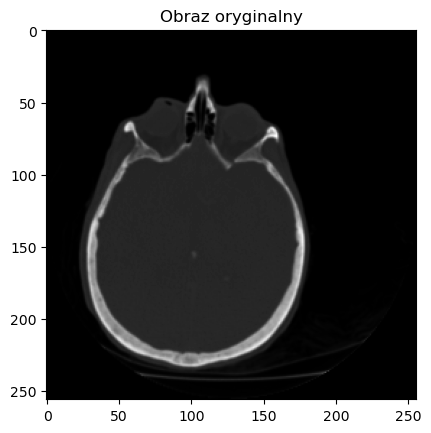

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform
import math

# Wczytanie przykładowego obrazu medycznego (np. skanu mózgu lub oka)
try:
    img = data.brain()[5, :, :]
except AttributeError:
    img = data.camera()

img = img / img.max()

plt.imshow(img, cmap='gray')
plt.title('Obraz oryginalny')
plt.show()

### Zadanie 1: Złożona transformacja

Twoim pierwszym zadaniem jest utworzenie złożonej macierzy transformacji i nałożenie jej na oryginalny obraz. Przekształcenie powinno:
1. Obrócić obraz o **45 stopni**.
2. Powiększyć go dwukrotnie (skala **x2** na obu osiach).
3. Przesunąć go o **30 pikseli w prawo** i **20 pikseli w dół**.

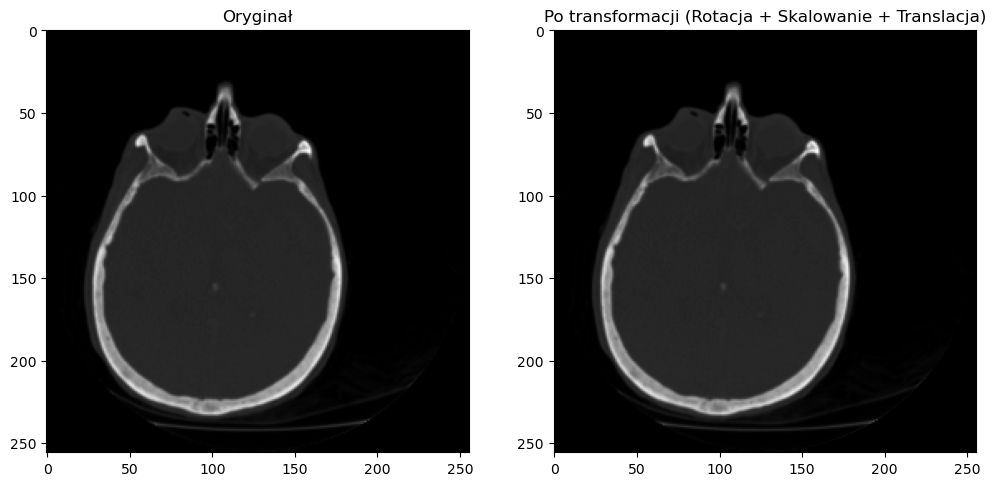

In [5]:
# -----------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Zadanie 1)
# -----------------------------------------------------

# TODO: Utwórz instancję transform.AffineTransform z odpowiednimi parametrami.
# Wskazówka: Kąty podajemy w radianach! (math.radians())
tform = None 

# TODO: Nałóż transformację na obraz 'img', używając funkcji transform.warp()
# Pamiętaj o odwrotnym mapowaniu! (tform.inverse)
warped_img = img # Zmień to!

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Oryginał')
ax[1].imshow(warped_img, cmap='gray')
ax[1].set_title('Po transformacji (Rotacja + Skalowanie + Translacja)')
plt.show()

### Zadanie 2: Pułapka interpolacji przy maskach segmentacyjnych

Zbudujmy sztuczną maskę segmentacyjną guza (obraz binarny, zawierający tylko 0 i 1). Zastosuj na niej prosty obrót o 20 stopni.

Następnie nałóż to przekształcenie **dwukrotnie**: raz domyślną interpolacją (dwuliniową, `order=1`), a drugi raz interpolacją najbliższego sąsiada (`order=0`).

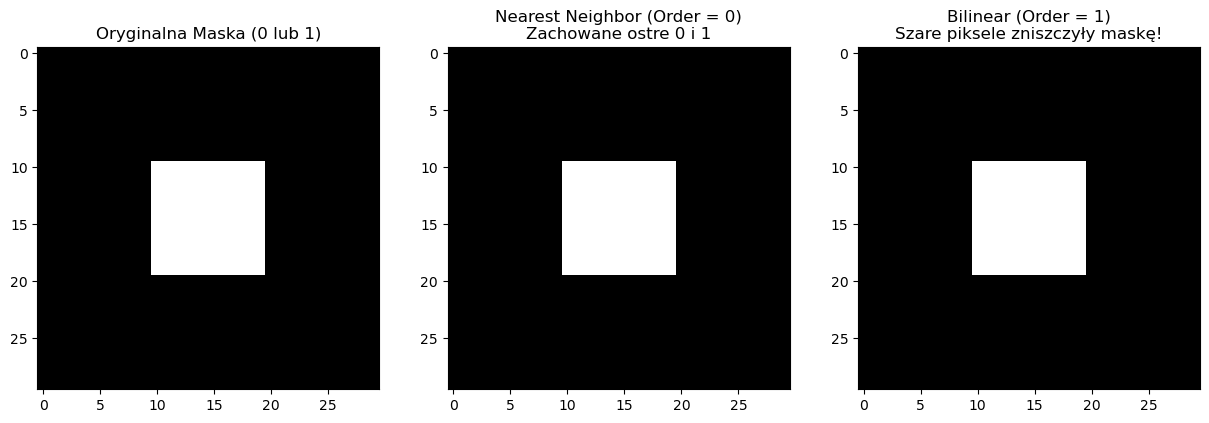

In [9]:
# Generowanie małej maski
mask_img = np.zeros((30, 30))
mask_img[10:20, 10:20] = 1.0

# -----------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Zadanie 2)
# -----------------------------------------------------

# TODO: Zdefiniuj transformację - obrót o 20 stopni
tform_rot = None 

# TODO: Nałóż transformację z różnymi parametrami 'order'
mask_order0 = mask_img  # Użyj order=0 (Nearest Neighbor)
mask_order1 = mask_img  # Użyj order=1 (Bilinear - domyślne)


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(mask_img, cmap='gray')
ax[0].set_title('Oryginalna Maska (0 lub 1)')

ax[1].imshow(mask_order0, cmap='gray')
ax[1].set_title('Nearest Neighbor (Order = 0)\nZachowane ostre 0 i 1')

ax[2].imshow(mask_order1, cmap='gray')
ax[2].set_title('Bilinear (Order = 1)\nSzare piksele zniszczyły maskę!')
plt.show()